# Experimento 2. Convergencia de Learned y RoPE

## 1. Configuración
Entrenaremos dos modelos independientes desde cero en OPUS100 y después continuaremos sus pesos en DACSA. Mantendremos iguales la arquitectura, los lotes, el orden de los datos, el optimizador y el número de actualizaciones. Usaremos AMP FP16 con parámetros FP32 en CUDA y FP32 en CPU.

Realizaremos **10.000 actualizaciones por fase y modelo**, sin parada temprana. Guardaremos las tablas en `resultados_exp2/` y las figuras PNG en `figuras_exp2/`; mantendremos el piloto en sus subcarpetas.

> Mostraremos las salidas del modo indicado en la configuración. Mantendremos separados el piloto y el entrenamiento definitivo para no confundir sus resultados.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from IPython.display import display

RAIZ = Path.cwd().resolve()
if not (RAIZ / 'minigpt').is_dir():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from minigpt.config import GPTConfig
from minigpt.model import GPTModel

EJECUTAR_DEFINITIVO = True
CFG = {
    'contexto': 512, 'dimension': 256, 'capas': 4, 'cabezas': 4, 'dropout': 0.0,
    'microlote': 16, 'acumulacion': 2, 'lr': 3e-4, 'weight_decay': 0.01,
    'max_norm_grad': 1.0, 'semilla': 42,
    'pasos_piloto': {'opus': 60, 'dacsa': 60},
    'pasos_definitivos': {'opus': 10000, 'dacsa': 10000},
    'evaluar_cada': 500, 'bloques_validacion': 2048,
}
MODO = 'definitivo' if EJECUTAR_DEFINITIVO else 'piloto'
PRESUPUESTOS = CFG['pasos_definitivos'] if EJECUTAR_DEFINITIVO else CFG['pasos_piloto']
if EJECUTAR_DEFINITIVO and any(p is None or p <= 0 for p in PRESUPUESTOS.values()):
    raise ValueError('Primero acordaremos los presupuestos definitivos de OPUS y DACSA.')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
if not AMP:
    torch.set_num_threads(4)
BASE = RAIZ / 'experimentos_2_y_3'
SALIDA = BASE / 'resultados_exp2'
FIGURAS = BASE / 'figuras_exp2'
if not EJECUTAR_DEFINITIVO:
    SALIDA = SALIDA / 'piloto'
    FIGURAS = FIGURAS / 'piloto'
CACHE = BASE / 'cache_datos_exp2'
for carpeta in (SALIDA, FIGURAS, CACHE):
    carpeta.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11, 'savefig.dpi': 250})

def sincronizar():
    if AMP:
        torch.cuda.synchronize(DEVICE)

def fijar_semilla():
    random.seed(CFG['semilla'])
    np.random.seed(CFG['semilla'])
    torch.manual_seed(CFG['semilla'])
    if AMP:
        torch.cuda.manual_seed_all(CFG['semilla'])
    torch.backends.cudnn.benchmark = False

print(f'Modo: {MODO} | Dispositivo: {DEVICE} | AMP FP16: {AMP}')
if AMP:
    print(torch.cuda.get_device_name(DEVICE))
print('Lote efectivo:', CFG['microlote'] * CFG['acumulacion'])

Modo: definitivo | Dispositivo: cuda | AMP FP16: True
NVIDIA GeForce RTX 5070 Laptop GPU
Lote efectivo: 32


## 2. Datos y vocabulario común
Primero leeremos OPUS train y valid tal como están preparados, sin abrir el test ni reutilizar el Parquet original. En DACSA reservaremos aproximadamente un 5 % de artículos para validación según el hash de su contenido. Dejaremos los artículos idénticos en la misma partición; no buscaremos duplicados aproximados.

Construiremos el vocabulario solo con **OPUS train y DACSA train**, sin usar validación. Separaremos los documentos con un salto de línea y guardaremos sus caracteres como `uint16` en disco. Los leeremos con `memmap` para no cargar los corpus completos en RAM. También en el piloto prepararemos las cachés completas, aunque entrenaremos pocos pasos.

In [2]:
FUENTES = {
    'opus_train': RAIZ / 'data' / 'opus100_en-es_train.txt',
    'opus_valid': RAIZ / 'data' / 'opus100_en-es_valid.txt',
    'dacsa': RAIZ / 'data' / 'dacsa_spanish_articles_train.txt',
}
for ruta in FUENTES.values():
    if not ruta.is_file():
        raise FileNotFoundError(ruta)
FIRMA = {'version': 1, 'particion_dacsa': 'sha256_contenido_mod100_valid_menor5',
         'fuentes': {k: [str(p), p.stat().st_size, p.stat().st_mtime_ns]
                     for k, p in FUENTES.items()}}

def documentos(clave):
    with FUENTES[clave].open(encoding='utf-8') as archivo:
        for linea in archivo:
            texto = linea.removesuffix(chr(10))
            if not texto.strip():
                continue
            if clave == 'dacsa':
                huella = hashlib.sha256(texto.encode('utf-8')).digest()
                particion = 'valid' if int.from_bytes(huella[:8], 'big') % 100 < 5 else 'train'
                destino = 'dacsa_' + particion
            else:
                destino = clave
            yield destino, texto + chr(10)

ruta_manifest = CACHE / 'manifest.json'
manifest = (json.loads(ruta_manifest.read_text(encoding='utf-8'))
            if ruta_manifest.is_file() else {})
claves = ['opus_train', 'opus_valid', 'dacsa_train', 'dacsa_valid']
cache_valida = (manifest.get('firma') == FIRMA and all(
    (CACHE / f'{k}.u16').is_file() and (CACHE / f'{k}.u16').stat().st_size
    == 2 * manifest.get('estadisticas', {}).get(k, {}).get('tokens', -1) for k in claves))

if not cache_valida:
    inicio_preparacion = time.perf_counter()
    caracteres = set()
    for clave in ('opus_train', 'dacsa'):
        print('Revisando vocabulario de entrenamiento:', clave, flush=True)
        for destino, texto in documentos(clave):
            if destino.endswith('_train'):
                caracteres.update(texto)
    caracteres = sorted(caracteres)
    stoi = {caracter: i for i, caracter in enumerate(caracteres)}
    ID_UNK = len(stoi)
    assert ID_UNK < 65535
    tabla_ids = np.full(0x110000, ID_UNK, dtype=np.uint16)
    for caracter, indice in stoi.items():
        tabla_ids[ord(caracter)] = indice
    estadisticas = {k: {'documentos': 0, 'tokens': 0, 'unk': 0} for k in claves}
    archivos = {k: (CACHE / f'{k}.tmp').open('wb') for k in claves}
    try:
        for clave in FUENTES:
            print('Codificando corpus completo:', clave, flush=True)
            for destino, texto in documentos(clave):
                codigos = np.frombuffer(texto.encode('utf-32-le'), dtype='<u4')
                ids = tabla_ids[codigos]
                archivos[destino].write(ids.tobytes())
                estadisticas[destino]['documentos'] += 1
                estadisticas[destino]['tokens'] += len(ids)
                estadisticas[destino]['unk'] += int(np.count_nonzero(ids == ID_UNK))
    finally:
        for archivo in archivos.values():
            archivo.close()
    for clave in claves:
        (CACHE / f'{clave}.tmp').replace(CACHE / f'{clave}.u16')
    manifest = {'firma': FIRMA, 'caracteres': caracteres, 'id_unk': ID_UNK,
                'estadisticas': estadisticas,
                'preparacion_s': time.perf_counter() - inicio_preparacion}
    ruta_manifest.write_text(json.dumps(manifest, ensure_ascii=True, indent=2), encoding='utf-8')

caracteres = manifest['caracteres']
stoi = {caracter: i for i, caracter in enumerate(caracteres)}
ID_UNK = manifest['id_unk']
VOCAB_SIZE = ID_UNK + 1
HUELLA_VOCAB = hashlib.sha256(json.dumps(caracteres, ensure_ascii=True).encode()).hexdigest()
assert all(manifest['estadisticas'][k]['unk'] == 0 for k in ('opus_train', 'dacsa_train'))
display(pd.DataFrame(manifest['estadisticas']).T)
print('Vocabulario común, incluido UNK:', VOCAB_SIZE)
print(f"Preparación inicial de las cachés: {manifest['preparacion_s']:.1f} s")
(SALIDA / 'datos_y_vocabulario.json').write_text(
    json.dumps(manifest, ensure_ascii=True, indent=2), encoding='utf-8')

,documentos,tokens,unk
opus_train,871322,160842348,0
opus_valid,29244,5386273,11
dacsa_train,680737,2333089221,0
dacsa_valid,35646,121135980,84


Vocabulario común, incluido UNK: 3374
Preparación inicial de las cachés: 113.6 s


53738

## 3. Ventanas y lotes
Barajaremos todas las ventanas de entrenamiento sin reemplazo y usaremos el mismo orden para ambos modelos. Cada actualización tendrá 32 secuencias, repartidas en dos microlotes de 16. Al acabar una pasada continuaremos con otra permutación y completaremos el lote pendiente. Solo dejaremos fuera la cola del corpus que no complete una ventana.

Para las curvas usaremos una muestra fija y repartida de validación: 128 ventanas en el piloto y 2.048 en el definitivo. Además, evaluaremos los checkpoints seleccionados de cada fase definitiva con toda su validación. No compararemos las pérdidas de OPUS y DACSA como si procedieran del mismo conjunto de datos.

In [3]:
class VentanasCausales(Dataset):
    def __init__(self, clave):
        self.tokens = np.memmap(CACHE / f'{clave}.u16', mode='r', dtype=np.uint16)
        self.contexto = CFG['contexto']

    def __len__(self):
        return (len(self.tokens) - 1) // self.contexto

    def __getitem__(self, indice):
        inicio = int(indice) * self.contexto
        return torch.from_numpy(np.array(
            self.tokens[inicio:inicio + self.contexto + 1], dtype=np.int64))

datasets = {clave: VentanasCausales(clave) for clave in claves}
LOTE_EFECTIVO = CFG['microlote'] * CFG['acumulacion']

def lotes_entrenamiento(fase, actualizaciones_previas=0):
    dataset = datasets[fase + '_train']
    generador = torch.Generator().manual_seed(
        CFG['semilla'] + (1000 if fase == 'opus' else 2000))
    pendientes = []
    consumidos = actualizaciones_previas * LOTE_EFECTIVO
    while True:
        orden = torch.randperm(len(dataset), generator=generador).numpy()
        if consumidos >= len(orden):
            consumidos -= len(orden)
            continue
        for indice in orden[consumidos:]:
            pendientes.append(int(indice))
            if len(pendientes) == LOTE_EFECTIVO:
                yield torch.stack([dataset[i] for i in pendientes])
                pendientes = []
        consumidos = 0

validadores = {}
for fase in ('opus', 'dacsa'):
    dataset = datasets[fase + '_valid']
    generador = torch.Generator().manual_seed(9000)
    cantidad = min(
        len(dataset), CFG['bloques_validacion'] if EJECUTAR_DEFINITIVO else 128)
    indices = torch.randperm(len(dataset), generator=generador)[:cantidad].tolist()
    validadores[fase] = DataLoader(
        Subset(dataset, indices), batch_size=CFG['microlote'], num_workers=0)

if EJECUTAR_DEFINITIVO and PRESUPUESTOS['opus'] * LOTE_EFECTIVO < len(datasets['opus_train']):
    raise ValueError('La fase OPUS definitiva debe recorrer al menos todas sus ventanas de entrenamiento.')

print('Actualizaciones necesarias para recorrer OPUS:',
      (len(datasets['opus_train']) + LOTE_EFECTIVO - 1) // LOTE_EFECTIVO)
print('Tokens objetivo por actualización:', LOTE_EFECTIVO * CFG['contexto'])

Actualizaciones necesarias para recorrer OPUS: 9818
Tokens objetivo por actualización: 16384


## 4. Modelos y checkpoints
### 4.1. Creación de los modelos
Usaremos `GPTConfig` y `GPTModel` del proyecto, sin modificar la atención ni RoPE. Prepararemos las funciones para crear ambos modelos y su optimizador AdamW.

In [4]:
def crear_modelo(positional):
    return GPTModel(GPTConfig(
        vocab_size=VOCAB_SIZE, context_length=CFG['contexto'], emb_dim=CFG['dimension'],
        n_heads=CFG['cabezas'], n_layers=CFG['capas'], drop_rate=CFG['dropout'],
        qkv_bias=True, positional=positional, rope_theta=10000.0))

def crear_optimizador(modelo):
    return torch.optim.AdamW(
        modelo.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])

### 4.2. Guardado y recuperación
Guardaremos pesos, configuración, AdamW, GradScaler, métricas y estados aleatorios para poder continuar. Empezaremos DACSA desde el checkpoint **final de OPUS**, no desde el mejor punto anterior ni desde pesos reinicializados. También conservaremos los mejores checkpoints de cada fase según su muestra fija de validación.

In [5]:
def ruta_checkpoint(nombre, archivo):
    carpeta = BASE / 'pesos' / nombre.lower()
    if not EJECUTAR_DEFINITIVO:
        carpeta = carpeta / 'piloto'
    carpeta.mkdir(parents=True, exist_ok=True)
    semilla = CFG['semilla']
    return carpeta / f'{archivo}_seed{semilla}.pt'

def guardar_checkpoint(ruta, modelo, optimizador, scaler, fase, pasos_fase,
                       pasos_globales, val_loss, segundos_fase=0.0):
    temporal = ruta.with_suffix('.tmp')
    torch.save({
        'model_config': vars(modelo.cfg).copy(),
        'model_state_dict': {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()},
        'optimizer_state_dict': optimizador.state_dict(), 'scaler_state_dict': scaler.state_dict(),
        'semilla': CFG['semilla'], 'fase': fase, 'modo': MODO,
        'pasos_fase': pasos_fase, 'pasos_globales': pasos_globales, 'val_loss': val_loss,
        'training_config': CFG, 'caracteres': caracteres, 'id_unk': ID_UNK,
        'huella_vocabulario': HUELLA_VOCAB, 'firma_datos': FIRMA,
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all() if AMP else [],
        'historial_pasos': registro_pasos, 'historial_validacion': registro_validacion,
        'historial_rendimiento': registro_rendimiento, 'segundos_fase': segundos_fase,
    }, temporal)
    temporal.replace(ruta)

def cargar_entrenamiento(ruta):
    global registro_pasos, registro_validacion, registro_rendimiento
    checkpoint = torch.load(ruta, map_location='cpu', weights_only=True)
    assert checkpoint['huella_vocabulario'] == HUELLA_VOCAB
    assert checkpoint['firma_datos'] == FIRMA and checkpoint['training_config'] == CFG
    assert checkpoint['modo'] == MODO
    modelo = GPTModel(GPTConfig(**checkpoint['model_config']))
    modelo.load_state_dict(checkpoint['model_state_dict'], strict=True)
    modelo.to(device=DEVICE, dtype=torch.float32)
    optimizador = crear_optimizador(modelo)
    optimizador.load_state_dict(checkpoint['optimizer_state_dict'])
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    torch.set_rng_state(checkpoint['torch_rng_state'])
    if AMP:
        torch.cuda.set_rng_state_all(checkpoint['cuda_rng_state'])
    assert all(p.dtype == torch.float32 for p in modelo.parameters())
    assert all(torch.equal(v.detach().cpu(), checkpoint['model_state_dict'][k])
               for k, v in modelo.state_dict().items())
    assert all(int(estado['step'].item()) == checkpoint['pasos_globales']
               for estado in optimizador.state.values())
    assert scaler.state_dict() == checkpoint['scaler_state_dict']
    registro_pasos = checkpoint['historial_pasos']
    registro_validacion = checkpoint['historial_validacion']
    registro_rendimiento = checkpoint['historial_rendimiento']
    return modelo, optimizador, scaler, checkpoint

### 4.3. Validación y actualización
Calcularemos la pérdida de validación y prepararemos cada actualización con acumulación de gradientes. Si GradScaler detecta un desbordamiento, repetiremos el mismo lote con una escala menor para mantener el mismo número de actualizaciones efectivas.

In [6]:
@torch.no_grad()
def evaluar(modelo, cargador):
    modelo.eval()
    suma, tokens = 0.0, 0
    for lote in cargador:
        lote = lote.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = modelo(lote[:, :-1])
            perdida = F.cross_entropy(logits.float().reshape(-1, VOCAB_SIZE),
                                      lote[:, 1:].reshape(-1), reduction='sum')
        suma += perdida.item()
        tokens += lote[:, 1:].numel()
    sincronizar()
    modelo.train()
    valor = suma / tokens
    if not np.isfinite(valor):
        raise ValueError('Validation loss no finita.')
    return valor

def actualizar(modelo, optimizador, scaler, lote):
    lote = lote.to(DEVICE)
    for intento in range(16):
        optimizador.zero_grad(set_to_none=True)
        perdida_media = 0.0
        for micro in lote.split(CFG['microlote']):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
                logits = modelo(micro[:, :-1])
                perdida = F.cross_entropy(logits.float().reshape(-1, VOCAB_SIZE),
                                          micro[:, 1:].reshape(-1)) / CFG['acumulacion']
            if not torch.isfinite(perdida).item():
                raise ValueError('Training loss no finita.')
            scaler.scale(perdida).backward()
            perdida_media += perdida.item()
        scaler.unscale_(optimizador)
        norma = torch.nn.utils.clip_grad_norm_(modelo.parameters(), CFG['max_norm_grad'])
        escala_anterior = scaler.get_scale()
        scaler.step(optimizador)
        scaler.update()
        if scaler.get_scale() >= escala_anterior:
            if not torch.isfinite(norma).item():
                raise ValueError('Gradientes no finitos.')
            return perdida_media, norma.item(), intento
    raise ValueError('FP16 no se estabiliza tras reducir repetidamente la escala.')

### 4.4. Comprobación de la inicialización
Comprobaremos que los parámetros comunes parten de los mismos valores, sin compartir almacenamiento. Después mostraremos el número de parámetros de cada modelo.

In [7]:
fijar_semilla()
modelo_learned = crear_modelo('learned')
fijar_semilla()
modelo_rope = crear_modelo('rope')
comunes = dict(modelo_learned.named_parameters())
for nombre, parametro in modelo_rope.named_parameters():
    assert torch.equal(parametro, comunes[nombre])
    assert parametro.data_ptr() != comunes[nombre].data_ptr()
del comunes, parametro
modelos_iniciales = {'Learned': modelo_learned, 'RoPE': modelo_rope}
del modelo_learned, modelo_rope
display(pd.DataFrame([{'modelo': nombre, 'parametros': sum(p.numel() for p in m.parameters())}
                      for nombre, m in modelos_iniciales.items()]))

,modelo,parametros
0,Learned,5018112
1,RoPE,4887040


## 5. Entrenamiento en dos fases
### 5.1. Registro de métricas
Registraremos pérdida de entrenamiento y validación, tokens, gradientes, reintentos FP16, tiempos y memoria. Excluiremos las cinco primeras actualizaciones al resumir la velocidad y mediremos el pico de memoria desde ese calentamiento.

En el definitivo guardaremos un checkpoint de progreso y sus métricas cada 500 actualizaciones. Si reanudamos, recuperaremos el orden de datos, pesos, AdamW y GradScaler, sin repetir las fases terminadas. Conservaremos el piloto en `piloto/`.

In [8]:
registro_pasos, registro_validacion, registro_rendimiento = [], [], []

def exportar_registros():
    for fase in ('opus', 'dacsa'):
        for registros, sufijo in ((registro_pasos, 'entrenamiento'), (registro_validacion, 'validacion')):
            filas = [f for f in registros if f['fase'] == fase]
            if filas:
                ruta = SALIDA / f'{fase}_{sufijo}.csv'
                pd.DataFrame(filas).to_csv(ruta.with_suffix('.tmp'), index=False)
                ruta.with_suffix('.tmp').replace(ruta)
    if registro_rendimiento:
        pd.DataFrame(registro_rendimiento).to_csv(SALIDA / 'rendimiento.csv', index=False)

def entrenar_fase(nombre, fase, modelo, optimizador, scaler, pasos_previos,
                  paso_inicial=0, segundos_previos=0.0):
    iterador = lotes_entrenamiento(fase, paso_inicial)
    total_pasos = PRESUPUESTOS[fase]
    cada = CFG['evaluar_cada'] if EJECUTAR_DEFINITIVO else 20
    validaciones_previas = [
        f for f in registro_validacion if f['modelo'] == nombre and f['fase'] == fase
    ]
    mejor_val = min((f['val_loss'] for f in validaciones_previas), default=float('inf'))
    val_loss = validaciones_previas[-1]['val_loss'] if validaciones_previas else float('inf')
    inicio_fase = time.perf_counter()
    primer_paso = paso_inicial + 1 if validaciones_previas else 0
    modelo.train()
    for paso in range(primer_paso, total_pasos + 1):
        if paso > 0:
            sincronizar()
            inicio = time.perf_counter()
            lote = next(iterador)
            perdida, norma, reintentos = actualizar(modelo, optimizador, scaler, lote)
            del lote
            sincronizar()
            segundos = time.perf_counter() - inicio
            registro_pasos.append({
                'modelo': nombre, 'fase': fase, 'paso_fase': paso,
                'paso_global': pasos_previos + paso, 'train_loss': perdida,
                'norma_gradiente': norma, 'reintentos_fp16': reintentos,
                'segundos': segundos, 'tokens': LOTE_EFECTIVO * CFG['contexto'],
            })
            if AMP and paso == 5:
                torch.cuda.reset_peak_memory_stats(DEVICE)
        if paso % cada == 0 or paso == total_pasos:
            sincronizar()
            inicio_validacion = time.perf_counter()
            val_loss = evaluar(modelo, validadores[fase])
            segundos_val = time.perf_counter() - inicio_validacion
            registro_validacion.append({
                'modelo': nombre, 'fase': fase, 'paso_fase': paso,
                'paso_global': pasos_previos + paso, 'val_loss': val_loss,
                'segundos_validacion': segundos_val,
                'tokens_validacion': len(validadores[fase].dataset) * CFG['contexto'],
            })
            if val_loss < mejor_val:
                mejor_val = val_loss
                guardar_checkpoint(ruta_checkpoint(nombre, f'best_{fase}'), modelo,
                                   optimizador, scaler, fase, paso, pasos_previos + paso, val_loss,
                                   segundos_previos + time.perf_counter() - inicio_fase)
            guardar_checkpoint(ruta_checkpoint(nombre, f'ultimo_{fase}'), modelo,
                               optimizador, scaler, fase, paso, pasos_previos + paso, val_loss,
                               segundos_previos + time.perf_counter() - inicio_fase)
            exportar_registros()
            print(f'{nombre} | {fase} | {paso}/{total_pasos} | val={val_loss:.4f}', flush=True)
    filas = [
        f for f in registro_pasos
        if f['modelo'] == nombre and f['fase'] == fase and f['paso_fase'] > 5
    ]
    tiempos = np.array([f['segundos'] for f in filas])
    registro_rendimiento.append({
        'modelo': nombre, 'fase': fase, 'actualizaciones': total_pasos,
        'segundos_por_actualizacion': float(tiempos.mean()),
        'desviacion_segundos': float(tiempos.std(ddof=1)),
        'tokens_s': LOTE_EFECTIVO * CFG['contexto'] / float(tiempos.mean()),
        'pico_asignado_mib': torch.cuda.max_memory_allocated(DEVICE) / 2**20 if AMP else None,
        'segundos_fase_con_validacion_y_guardado': segundos_previos + time.perf_counter() - inicio_fase,
    })
    guardar_checkpoint(ruta_checkpoint(nombre, f'{fase}_final'), modelo, optimizador,
                       scaler, fase, total_pasos, pasos_previos + total_pasos, val_loss,
                       segundos_previos + time.perf_counter() - inicio_fase)
    exportar_registros()

### 5.2. Ejecución o reanudación
A continuación entrenaremos primero Learned y después RoPE, con un solo modelo en GPU. Completaremos OPUS antes de pasar a DACSA y mantendremos las 10.000 actualizaciones por fase. Si ya existen checkpoints, continuaremos desde el progreso guardado.

In [9]:
for nombre in ('Learned', 'RoPE'):
    fijar_semilla()
    for fase in ('opus', 'dacsa'):
        final = ruta_checkpoint(nombre, f'{fase}_final')
        progreso = ruta_checkpoint(nombre, f'ultimo_{fase}')
        completada = final.is_file()
        if completada or progreso.is_file():
            modelo, optimizador, scaler, estado = cargar_entrenamiento(final if completada else progreso)
            assert estado['fase'] == fase
            paso_inicial = estado['pasos_fase']
            pasos_previos = estado['pasos_globales'] - paso_inicial
            segundos_previos = estado['segundos_fase']
            if completada:
                assert paso_inicial == PRESUPUESTOS[fase]
            print(f'{nombre} | {fase}: restaurado paso {paso_inicial}.', flush=True)
            del estado
        elif fase == 'dacsa':
            modelo, optimizador, scaler, estado = cargar_entrenamiento(ruta_checkpoint(nombre, 'opus_final'))
            paso_inicial, pasos_previos, segundos_previos = 0, estado['pasos_globales'], 0.0
            del estado
            print(f'{nombre}: pesos, AdamW y GradScaler de OPUS restaurados.', flush=True)
        else:
            modelo = modelos_iniciales.pop(nombre).to(device=DEVICE, dtype=torch.float32)
            optimizador = crear_optimizador(modelo)
            scaler = torch.amp.GradScaler('cuda', enabled=AMP)
            paso_inicial, pasos_previos, segundos_previos = 0, 0, 0.0
        if not completada:
            entrenar_fase(
                nombre, fase, modelo, optimizador, scaler, pasos_previos,
                paso_inicial, segundos_previos)
        del modelo, optimizador, scaler
        if AMP:
            torch.cuda.empty_cache()
    modelos_iniciales.pop(nombre, None)

Learned | opus: restaurado paso 10000.


Learned | dacsa: restaurado paso 10000.


RoPE | opus: restaurado paso 10000.


RoPE | dacsa: restaurado paso 10000.


### 5.3. Tablas del entrenamiento
Comprobaremos que las métricas sean finitas y que ambos modelos hayan completado el presupuesto. Guardaremos los registros y la configuración, y mostraremos las tablas de rendimiento y validación.

In [10]:
tabla_pasos = pd.DataFrame(registro_pasos)
tabla_validacion = pd.DataFrame(registro_validacion)
tabla_rendimiento = pd.DataFrame(registro_rendimiento)
assert np.isfinite(tabla_pasos.select_dtypes('number')).all().all()
assert np.isfinite(tabla_validacion.select_dtypes('number')).all().all()
for fase in ('opus', 'dacsa'):
    for nombre in ('Learned', 'RoPE'):
        assert len(tabla_pasos[(tabla_pasos.fase == fase) & (tabla_pasos.modelo == nombre)]) == PRESUPUESTOS[fase]
    tabla_pasos[tabla_pasos.fase == fase].to_csv(SALIDA / f'{fase}_entrenamiento.csv', index=False)
    tabla_validacion[tabla_validacion.fase == fase].to_csv(SALIDA / f'{fase}_validacion.csv', index=False)
tabla_rendimiento.to_csv(SALIDA / 'rendimiento.csv', index=False)
(SALIDA / 'configuracion.json').write_text(json.dumps(
    {'modo': MODO, 'configuracion': CFG, 'gpu': torch.cuda.get_device_name(DEVICE) if AMP else None,
     'pytorch': torch.__version__, 'precision': 'AMP FP16, parametros FP32' if AMP else 'FP32',
     'huella_vocabulario': HUELLA_VOCAB}, indent=2), encoding='utf-8')
display(tabla_rendimiento.round(3))
display(tabla_validacion.round(4))

,modelo,fase,actualizaciones,segundos_por_actualizacion,desviacion_segundos,tokens_s,pico_asignado_mib,segundos_fase_con_validacion_y_guardado
0,Learned,opus,10000,0.116,0.004,141572.491,1769.652,1223.880
1,Learned,dacsa,10000,0.114,0.009,143590.154,1769.991,1202.364
2,RoPE,opus,10000,0.115,0.003,142600.015,1769.724,1212.454
3,RoPE,dacsa,10000,0.115,0.004,142039.442,1770.327,1220.305


,modelo,fase,paso_fase,paso_global,val_loss,segundos_validacion,tokens_validacion
0,Learned,opus,0,0,8.2558,3.2048,1048576
1,Learned,opus,500,500,1.8638,2.6771,1048576
2,Learned,opus,1000,1000,1.7054,2.6716,1048576
3,Learned,opus,1500,1500,1.4696,2.6593,1048576
4,Learned,opus,2000,2000,1.3532,2.6466,1048576
...,...,...,...,...,...,...,...
79,RoPE,dacsa,8000,18000,1.0957,2.6204,1048576
80,RoPE,dacsa,8500,18500,1.0914,2.6294,1048576
81,RoPE,dacsa,9000,19000,1.0884,2.6402,1048576
82,RoPE,dacsa,9500,19500,1.0853,2.6214,1048576


## 6. Curvas de convergencia
Después compararemos la evolución de la pérdida de ambos modelos en cada fase. Mostraremos el entrenamiento con una media móvil de 10 pasos y la validación fija. En la curva conjunta marcaremos el paso de OPUS a DACSA; no interpretaremos el salto entre corpus como una mejora o un empeoramiento directo.

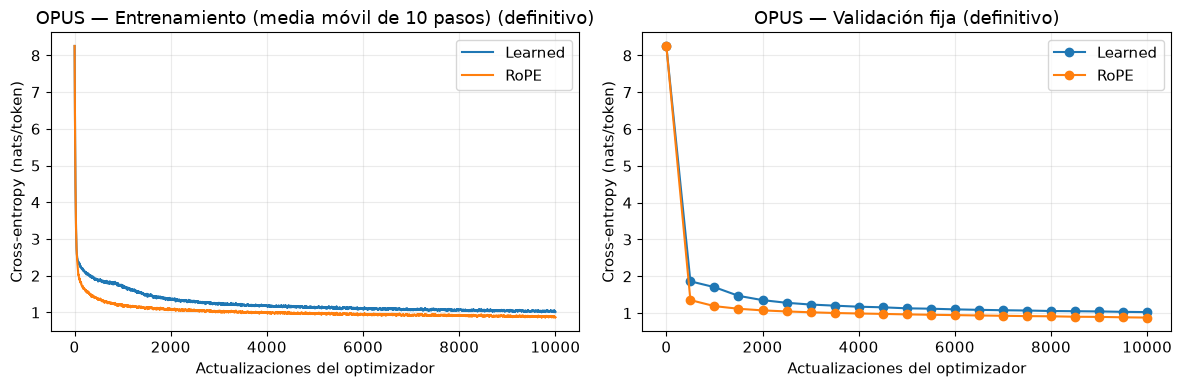

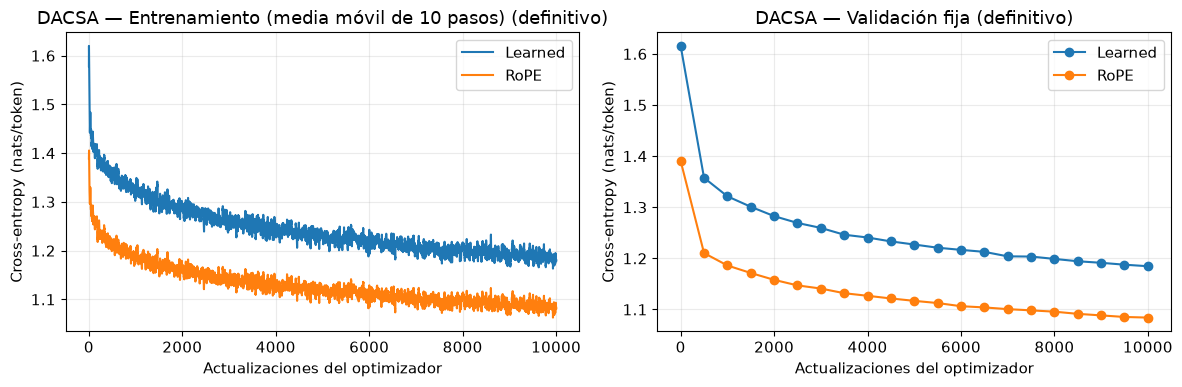

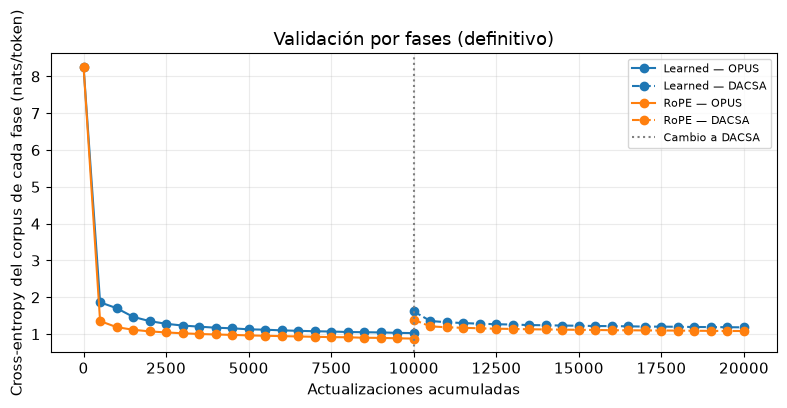

In [11]:
for fase in ('opus', 'dacsa'):
    figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
    for nombre in ('Learned', 'RoPE'):
        train = tabla_pasos[(tabla_pasos.fase == fase) & (tabla_pasos.modelo == nombre)]
        valid = tabla_validacion[(tabla_validacion.fase == fase) & (tabla_validacion.modelo == nombre)]
        ejes[0].plot(train.paso_fase, train.train_loss.rolling(10, min_periods=1).mean(), label=nombre)
        ejes[1].plot(valid.paso_fase, valid.val_loss, marker='o', label=nombre)
    for eje, titulo in zip(ejes, ('Entrenamiento (media móvil de 10 pasos)', 'Validación fija')):
        eje.set(title=f'{fase.upper()} — {titulo} ({MODO})',
                xlabel='Actualizaciones del optimizador', ylabel='Cross-entropy (nats/token)')
        eje.grid(alpha=0.25)
        eje.legend()
    figura.tight_layout()
    figura.savefig(FIGURAS / f'convergencia_{fase}.png')
    plt.show()

figura, eje = plt.subplots()
for nombre in ('Learned', 'RoPE'):
    color = 'tab:blue' if nombre == 'Learned' else 'tab:orange'
    for fase in ('opus', 'dacsa'):
        filas = tabla_validacion[(tabla_validacion.modelo == nombre) & (tabla_validacion.fase == fase)]
        eje.plot(filas.paso_global, filas.val_loss, marker='o', color=color,
                 linestyle='-' if fase == 'opus' else '--', label=f'{nombre} — {fase.upper()}')
eje.axvline(PRESUPUESTOS['opus'], color='gray', linestyle=':', label='Cambio a DACSA')
eje.set(title=f'Validación por fases ({MODO})', xlabel='Actualizaciones acumuladas',
        ylabel='Cross-entropy del corpus de cada fase (nats/token)')
eje.grid(alpha=0.25)
eje.legend(fontsize=8)
figura.tight_layout()
figura.savefig(FIGURAS / 'convergencia_fases.png')
plt.show()

## 7. Comprobación de los checkpoints
Por último cargaremos los mejores checkpoints de ambas fases con `model_config` y `model_state_dict`, el mismo formato que usará el experimento 3 con DACSA. Comprobaremos que los pesos y los logits sean finitos. En modo definitivo también evaluaremos cada checkpoint seleccionado sobre toda la validación de su fase y guardaremos la tabla de comprobaciones.

In [12]:
comprobaciones = []
for nombre in ('Learned', 'RoPE'):
    for fase in ('opus', 'dacsa'):
        ruta = ruta_checkpoint(nombre, f'best_{fase}')
        checkpoint = torch.load(ruta, map_location='cpu', weights_only=True)
        modelo = GPTModel(GPTConfig(**checkpoint['model_config']))
        modelo.load_state_dict(checkpoint['model_state_dict'], strict=True)
        assert all(p.dtype == torch.float32 and torch.isfinite(p).all() for p in modelo.parameters())
        modelo.to(DEVICE).eval()
        entrada = datasets[fase + '_valid'][0][:-1].unsqueeze(0).to(DEVICE)
        with torch.inference_mode(), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            salida = modelo(entrada)
        assert torch.isfinite(salida).all().item()
        fila = {'modelo': nombre, 'fase': fase, 'checkpoint': str(ruta),
                'paso_seleccionado': checkpoint['pasos_fase'], 'val_loss_muestra': checkpoint['val_loss']}
        if EJECUTAR_DEFINITIVO:
            cargador = DataLoader(datasets[fase + '_valid'], batch_size=CFG['microlote'], num_workers=0)
            inicio = time.perf_counter()
            fila['val_loss_completa'] = evaluar(modelo, cargador)
            fila['segundos_validacion_completa'] = time.perf_counter() - inicio
        comprobaciones.append(fila)
        del entrada, salida, modelo, checkpoint
        if AMP:
            torch.cuda.empty_cache()
tabla_checkpoints = pd.DataFrame(comprobaciones)
tabla_checkpoints.to_csv(SALIDA / 'checkpoints_verificados.csv', index=False)
display(tabla_checkpoints)
print('Piloto terminado; no se ha ejecutado el entrenamiento definitivo.' if not EJECUTAR_DEFINITIVO
      else 'Las dos fases definitivas han terminado.')

,modelo,fase,checkpoint,paso_seleccionado,val_loss_muestra,val_loss_completa,segundos_validacion_completa
0,Learned,opus,C:\Users\cavir.ROG-CARLOS\Desktop\PLN-Practica...,10000,1.027807,1.029150,12.757436
1,Learned,dacsa,C:\Users\cavir.ROG-CARLOS\Desktop\PLN-Practica...,10000,1.184643,1.186351,288.932271
2,RoPE,opus,C:\Users\cavir.ROG-CARLOS\Desktop\PLN-Practica...,10000,0.878856,0.881541,13.366860
3,RoPE,dacsa,C:\Users\cavir.ROG-CARLOS\Desktop\PLN-Practica...,10000,1.084145,1.086201,300.872739


Las dos fases definitivas han terminado.
